# VLA：视觉、语言与状态到动作 chunk

[English](01_finetune.ipynb) | 简体中文

## Goal

CLIP 视觉/语言编码器 + 状态 + 连续动作 head 的行为克隆基线；不是 OpenVLA checkpoint。

本教程执行：校验数据 → 训练 → validation 选模 → test 报告 → 保存/重新加载 → 推理 → epoch 断点恢复 → 发布包预览。

**全部数据为合成样例，tiny 权重随机初始化。这里验证工程链路，不证明实际模型质量。** 首版只支持单进程、单设备 fp32，默认 CPU，无需下载模型。

## Setup

本地先运行 `python -m pip install -e '.[vla,notebooks]'`。Colab 中下一格会克隆仓库并安装依赖；真实训练前把数据与输出放到 Google Drive 等持久化存储，避免运行时断开后丢失。

In [1]:
import os
import subprocess
import sys
from pathlib import Path

if "google.colab" in sys.modules:
    checkout = Path("/content/advai-notebooks")
    if not checkout.exists():
        subprocess.run(["git", "clone", "--depth", "1",
                        "https://github.com/advai-x/advai-notebooks.git", str(checkout)], check=True)
    subprocess.run([sys.executable, "-m", "pip", "install", "-e",
                    f"{checkout}[vla,notebooks]"], check=True)
    os.chdir(checkout)

ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "pyproject.toml").is_file())
sys.path.insert(0, str(ROOT / "src"))
print("Repository ready; install .[vla,notebooks] locally if needed.")

Repository ready; install .[vla,notebooks] locally if needed.


## Steps — 配置和数据检查

新输出目录避免覆盖旧实验。数据必须包含独立的 train / validation / test；source group、episode 与重复内容不能跨 split。归一化（VLA/VM）只使用 train。

In [2]:
import json
from uuid import uuid4

from advai_notebooks.common.runtime import setup
from advai_notebooks.vla.config import load_config
from advai_notebooks.vla.data import load_data, prepare_data
from advai_notebooks.vla.model import VLAModel
from advai_notebooks.vla.pipeline import run
from advai_notebooks.vla.evaluate import evaluate
from advai_notebooks.vla.publish import publish
from transformers.utils import logging
logging.disable_progress_bar()

cfg = load_config(ROOT / "configs/vla/smoke.yaml")
cfg.output_dir = f"outputs/vla/notebook-{uuid4().hex[:8]}"
# Set cfg.model.freeze_backbone = False BEFORE run for full encoder updates.
model = VLAModel(cfg.model, setup(cfg), cfg.root, cfg.training)
rows, summary = load_data(cfg)
prepared = prepare_data(rows, model, cfg, fit=True)
print(json.dumps({"data": summary, "prepared_rows": {k: len(v) for k, v in prepared.items()}}, indent=2))

{
  "data": {
    "rows": 4,
    "splits": {
      "train": 2,
      "validation": 1,
      "test": 1
    },
    "fingerprint": "8434241b0b3a333bb43036d189746cd37e7c6cd0fe7036fd94adceb509efbd36",
    "steps": 12,
    "media_fingerprint": "55eba803c3b9ac4075afd3467e717907e77033f367dd037c2b85140ae613131a"
  },
  "prepared_rows": {
    "train": 6,
    "validation": 3,
    "test": 3
  }
}


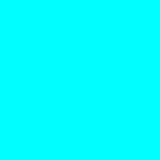

{'instruction': 'move up', 'state': [0, 0.1]}


In [3]:
from PIL import Image
from IPython.display import display

example = next(row for row in rows if row["split"] == "test")
display(Image.open(example["image"]).resize((160, 160), resample=Image.Resampling.NEAREST))
print({"instruction": example["instruction"], "state": example["state"]})

### 训练、验证与选模

选模使用 validation 的 原始动作空间 MSE（越低越好），包括 epoch 0 基线；test 不参与选模。

`export/` 保存 validation 最优模型，`latest_export/` 保存最后一轮。保留 baseline、每轮 checkpoint、优化器/RNG、环境与数据/来源指纹。

In [4]:
report = run(cfg)
print(json.dumps({
    "baseline_test": report["baseline_test"]["metrics"],
    "selected_test": report["finetuned_test"]["metrics"],
    "selected_epoch": report["training"]["best_epoch"],
    "completed_epoch": report["training"]["epoch"],
}, indent=2))
assert report["training"]["epoch"] == cfg.training.epochs

{
  "baseline_test": {
    "action_mse": 0.00797790326178074,
    "action_mae": 0.07684151530265808
  },
  "selected_test": {
    "action_mse": 0.006494909711182118,
    "action_mae": 0.06808139979839326
  },
  "selected_epoch": 2,
  "completed_epoch": 2
}


## Checks — 原生导出、重新加载与推理

重新加载后重新计算 held-out 指标，并检查与训练报告一致。tiny 生成文本/动作/状态只用于接口演示，不应用于业务或机器人执行。

In [5]:
loaded = VLAModel.load(report["export"])
reloaded_metrics = evaluate(loaded, prepare_data(rows, loaded, cfg, fit=False), cfg, "test")
assert reloaded_metrics["metrics"] == report["finetuned_test"]["metrics"]
prediction = loaded.predict(example["image"], example["instruction"], example["state"])
assert len(prediction["actions"]) == cfg.model.horizon
assert all(len(a) == cfg.model.action_dim for a in prediction["actions"])
print(json.dumps(prediction, indent=2))

{
  "actions": [
    [
      0.07045648247003555,
      0.08611971884965897
    ],
    [
      0.06238237023353577,
      0.0518205463886261
    ]
  ],
  "action_spec": {
    "state_names": [
      "x",
      "y"
    ],
    "state_units": "meters",
    "action_names": [
      "dx",
      "dy"
    ],
    "action_units": "meters",
    "coordinate_frame": "world",
    "control_frequency_hz": 10.0,
    "horizon": 2,
    "action_dim": 2
  }
}


### 严格 epoch 断点恢复

下面从已完成实验恢复（幂等，不再训练）。中途退出时也是同一个入口，从最新已完成 epoch 继续。配置、数据、源码、相关依赖必须不变；精确中断恢复由回归测试覆盖。

In [6]:
resumed = run(cfg, resume=cfg.path(cfg.output_dir) / "latest")
assert resumed["training"] == report["training"]
print({"resume_epoch": resumed["training"]["epoch"], "history_unchanged": True})

{'resume_epoch': 2, 'history_unchanged': True}


### 离线发布预览

仅检查推理文件白名单和重新加载，不连接 Hub、不创建仓库、不上传数据。真正发布需要显式去掉 dry_run，并确认基座许可证、数据授权与模型卡。

In [7]:
plan = publish(report["export"], "example/vla-training-guide", dry_run=True)
assert plan["status"] == "dry_run"
names = [item["path"] for item in plan["files"]]
assert not any("training_state" in name for name in names)
print({"status": plan["status"], "inference_files": names})

{'status': 'dry_run', 'inference_files': ['README.md', 'action_head.safetensors', 'advai_metadata.json', 'encoder/config.json', 'encoder/model.safetensors', 'encoder/processor_config.json', 'encoder/tokenizer.json', 'encoder/tokenizer_config.json']}


## Next Steps

- [完整 Guide](../../docs/vla.zh-CN.md)：数据字段、推理 JSON、方法与局限。
- [配置目录](../../configs/vla/README.md)：冻结/full smoke 和固定 CLIP revision 的预训练编码器模板；动作 head 仍从随机开始。
- 先用 smoke 检查数据契约；真实配置的模型感知校验会加载权重，同样需要足够硬件内存。更换数据或配置时使用新的输出目录。
- 对真实任务增加适当指标与人工检查：闭环任务成功率与动作限制，不能把离线 MSE 当成机器人安全保证。

CPU smoke 和输出重新加载已执行；CUDA/MPS、大型真实基座训练及机器人/视频能力不在本 Notebook 验证范围内。